In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [6]:
train = pd.read_csv("../data/customer_churn_dataset-training-master.csv")
test = pd.read_csv("../data/customer_churn_dataset-testing-master.csv")

df = pd.concat([train, test], ignore_index=True)

In [7]:
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "")
print(df.columns)   # check once

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'UsageFrequency',
       'SupportCalls', 'PaymentDelay', 'SubscriptionType', 'ContractLength',
       'TotalSpend', 'LastInteraction', 'Churn'],
      dtype='object')


In [8]:
# Fix MonthlyCharges (only if exists)
if 'MonthlyCharges' in df.columns:
    df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
    df['MonthlyCharges'].fillna(df['MonthlyCharges'].median(), inplace=True)

# Fix TotalCharges (if exists)
if 'TotalCharges' in df.columns:
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Fill remaining missing values
df.fillna(method='ffill', inplace=True)

C:\Users\Rachit kumar\AppData\Local\Temp\ipykernel_23040\1241750708.py:12: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)


In [9]:
le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

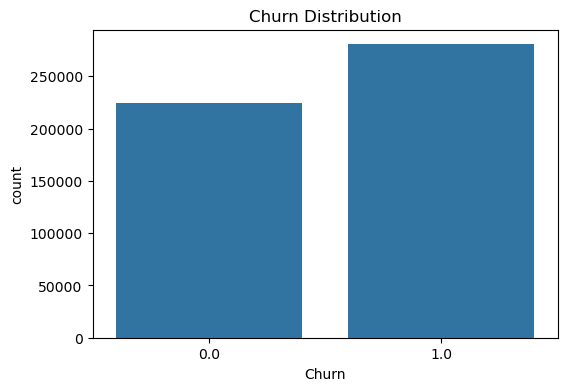

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

In [11]:
if 'MonthlyCharges' in df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
    plt.title("Monthly Charges vs Churn")
    plt.show()

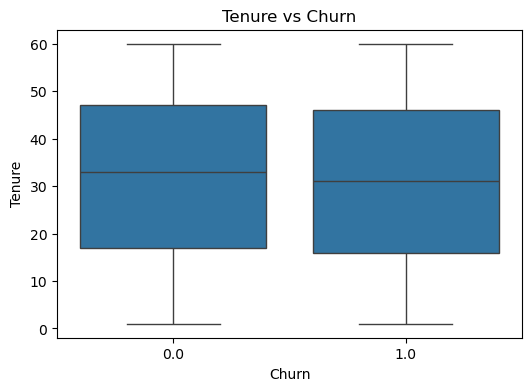

In [12]:
if 'Tenure' in df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Churn', y='Tenure', data=df)
    plt.title("Tenure vs Churn")
    plt.show()

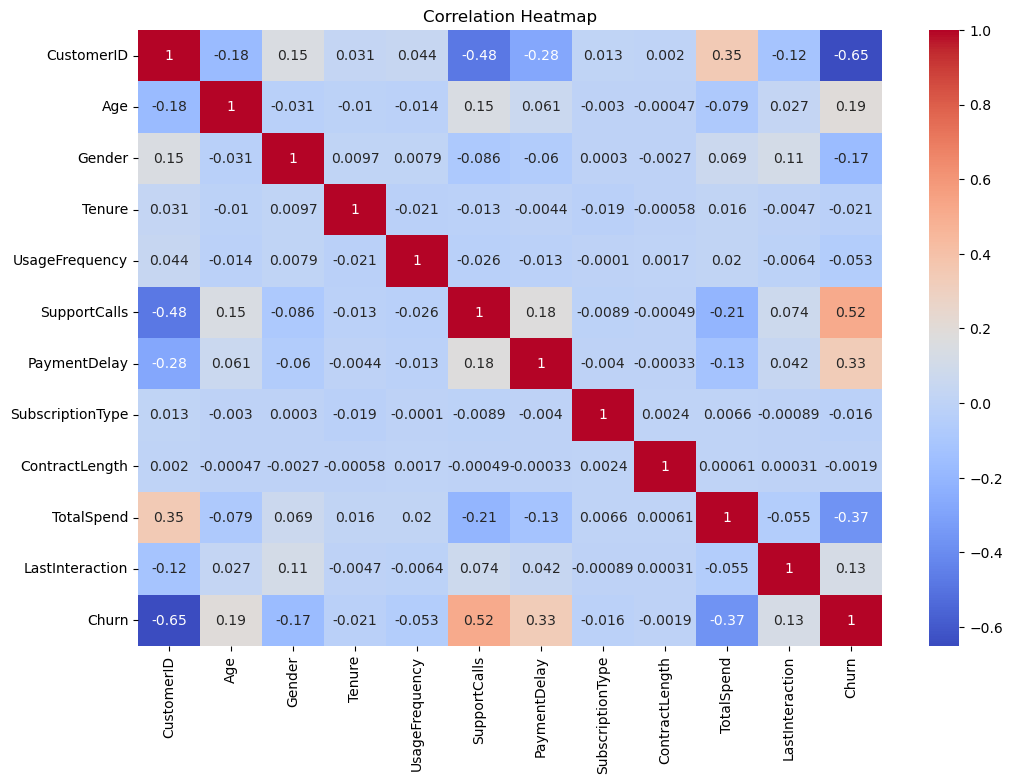

In [13]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
#Model Building
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [15]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

c:\Anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [16]:
y_pred = model.predict(X_test)

In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.873468458660755

Confusion Matrix:
 [[37801  7162]
 [ 5623 50456]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.87      0.84      0.86     44963
         1.0       0.88      0.90      0.89     56079

    accuracy                           0.87    101042
   macro avg       0.87      0.87      0.87    101042
weighted avg       0.87      0.87      0.87    101042



In [20]:
print(df.columns.tolist())

['CustomerID', 'Age', 'Gender', 'Tenure', 'UsageFrequency', 'SupportCalls', 'PaymentDelay', 'SubscriptionType', 'ContractLength', 'TotalSpend', 'LastInteraction', 'Churn']


In [21]:
for col in df.columns:
    if 'charge' in col.lower():
        print(col)

In [22]:
sns.histplot(df['Monthly Charges'], kde=True)
plt.title("Distribution of Monthly Charges")
plt.show()

KeyError: 'Monthly Charges'